# Credit Card Fraud Detection

Machine learning project for detecting fraudulent credit card transactions.

## Project Goals
- Explore the credit card transaction dataset
- Build and compare multiple classification models
- Handle severe class imbalance
- Explain model predictions using SHAP
- Track experiments with MLflow
- Assess model drift and monitoring readiness

In [1]:
import sys

print("Python version:", sys.version)


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("All imports successful")

All imports successful


In [3]:
!pip install -q imbalanced-learn xgboost lightgbm shap mlflow evidently

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 4.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 3.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 97.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 106.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 47.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 67.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 271.4/271.4 kB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [4]:
import imblearn
import xgboost
import shap
import mlflow
import lightgbm
import evidently
print("All imports success")

All imports success


# Credit Card Fraud Detection

## 1. Project Definition

## 2. Environment & Experiment Tracking

## 3. Dataset

## 4. Exploratory Data Analysis

## 5. Data Preprocessing

## 6. Baseline Models

## 7. Model Evaluation

## 8. Class Imbalance & SMOTE

## 9. Model Explainability with SHAP

## 10. Model Drift & Monitoring

## 11. Conclusions

In [5]:
import mlflow

mlflow.set_experiment("credit-card-fraud-detection")

print("MLflow experiment created!")

2026/10/12 08:30:16 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/12 08:30:16 INFO mlflow.store.db.utils: Updating database tables
2026/10/12 08:30:23 INFO mlflow.tracking.fluent: Experiment with name 'credit-card-fraud-detection' does not exist. Creating a new experiment.


MLflow experiment created!


In [6]:
import mlflow

with mlflow.start_run():
  mlflow.log_param("model", "test")
  mlflow.log_param("purpose", "testing MLflow setup")
  mlflow.log_metric("test_accuracy", 0.95)

print("First MLflow run completed")


First MLflow run completed


In [10]:
import pandas as pd
df = pd.read_csv("/content/creditcard.csv")
print("dataset load success")
print("Shape: ", df.shape)


dataset load success
Shape:  (69415, 31)


In [13]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 69415 entries, 0 to 69414
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    69415 non-null  int64  
 1   V1      69415 non-null  float64
 2   V2      69415 non-null  float64
 3   V3      69415 non-null  float64
 4   V4      69415 non-null  float64
 5   V5      69415 non-null  float64
 6   V6      69415 non-null  float64
 7   V7      69415 non-null  float64
 8   V8      69415 non-null  float64
 9   V9      69415 non-null  float64
 10  V10     69415 non-null  float64
 11  V11     69415 non-null  float64
 12  V12     69415 non-null  float64
 13  V13     69415 non-null  float64
 14  V14     69414 non-null  float64
 15  V15     69414 non-null  float64
 16  V16     69414 non-null  float64
 17  V17     69414 non-null  float64
 18  V18     69414 non-null  float64
 19  V19     69414 non-null  float64
 20  V20     69414 non-null  float64
 21  V21     69414 non-null  float64
 22

In [15]:
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [16]:
df["Class"].value_counts()

,count
Class,
0.0,69241
1.0,173


In [17]:
class_counts = df["Class"].value_counts()
class_percentage = df["Class"].value_counts(normalize=True) * 100

print("Trans counts: ", class_counts)
print("Trans percentage: ", class_percentage)


Trans counts:  Class
0.0    69241
1.0      173
Name: count, dtype: int64
Trans percentage:  Class
0.0    99.750771
1.0     0.249229
Name: proportion, dtype: float64


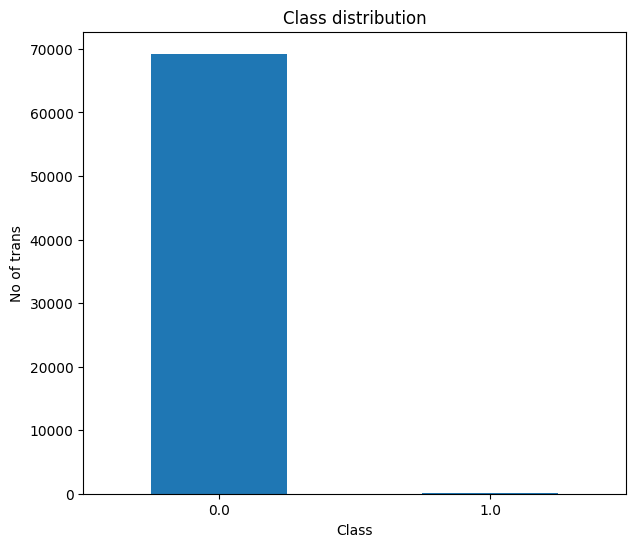

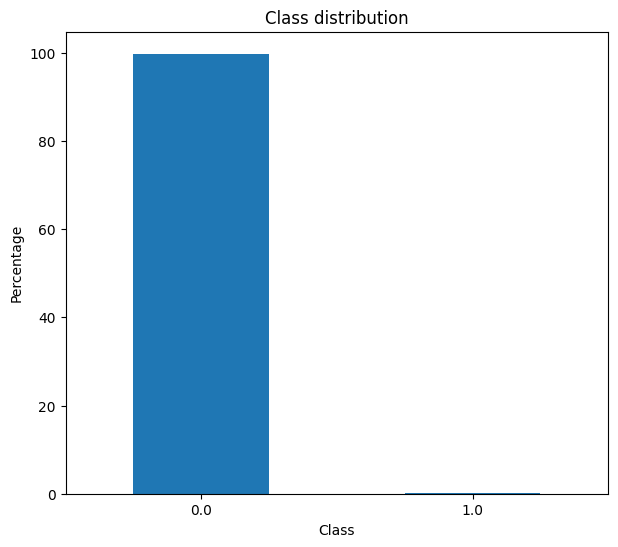

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,6))
class_counts.plot(kind = "bar")

plt.title("Class distribution")
plt.xlabel("Class")
plt.ylabel("No of trans")
plt.xticks(rotation = 0)

plt.figure(figsize=(7,6))
class_percentage.plot(kind = "bar")

plt.title("Class distribution")
plt.xlabel("Class")
plt.ylabel("Percentage")
plt.xticks(rotation = 0)

plt.show()

The dataset is highly imbalanced with approx 99.83% legit transactions and only 0.17% fraud transactions.
Accuracy will not be a meaningfull evaluation metric because the fraud class is rare. This dataset predicts every transaction as legit and fails to detect fraud.
Instead we can use precision and recall metrics. Precision -> when I say fraud, how often am I right? Recall -> How many frauds did I actually identify out of all the fraud ones.

In [19]:
pca_features = [f"V{i}" for i in range(1, 29)]

df[pca_features].describe().T

,count,mean,std,min,25%,50%,75%,max
V1,69415.0,-0.244558,1.867033,-56.407510,-1.004689,-0.242838,1.153743,1.960497
V2,69415.0,-0.020747,1.655570,-72.715728,-0.592001,0.071695,0.727593,18.902453
V3,69415.0,0.681822,1.420627,-33.680984,0.195519,0.770956,1.403552,4.226108
V4,69415.0,0.168990,1.376156,-5.172595,-0.724951,0.187901,1.051334,16.715537
V5,69415.0,-0.271065,1.394497,-42.147898,-0.888408,-0.303080,0.268315,34.801666
V6,69415.0,0.101799,1.308084,-26.160506,-0.636397,-0.150180,0.494961,22.529298
V7,69415.0,-0.115054,1.261332,-31.764946,-0.604542,-0.074759,0.420173,36.677268
V8,69415.0,0.057321,1.237094,-73.216718,-0.141264,0.066544,0.344727,20.007208
V9,69415.0,0.022473,1.163167,-9.283925,-0.670457,-0.069000,0.676925,10.392889
V10,69415.0,-0.039057,1.093202,-18.271168,-0.512005,-0.098475,0.436352,13.198226


In [20]:
df[pca_features].var().sort_values(ascending=False)

,0
V1,3.485811
V2,2.740913
V3,2.018181
V5,1.944621
V4,1.893806
V6,1.711084
V7,1.590958
V8,1.530402
V12,1.499662
V9,1.352957


In [21]:
df.groupby("Class")[pca_features].mean().T

Class,0.0,1.0
V1,-0.227869,-6.933421
V2,-0.033289,5.000911
V3,0.706865,-9.340224
V4,0.155935,5.397284
V5,-0.258839,-5.161426
V6,0.107358,-2.120226
V7,-0.097214,-7.252875
V8,0.048905,3.426366
V9,0.030613,-3.228419
V10,-0.022054,-6.849965


In [22]:
feature_means = df.groupby("Class")[pca_features].mean().T

feature_means["absolute_difference"] = (feature_means[0] - feature_means[1]).abs()

feature_means.sort_values(
    "absolute_difference",
    ascending=False,
).head(10)

Class,0.0,1.0,absolute_difference
V3,0.706865,-9.340224,10.047089
V17,0.107966,-8.984423,9.092388
V14,0.126508,-8.162145,8.288653
V12,-0.168228,-7.836955,7.668727
V7,-0.097214,-7.252875,7.155661
V10,-0.022054,-6.849965,6.827912
V1,-0.227869,-6.933421,6.705552
V16,0.004872,-5.320248,5.325120
V4,0.155935,5.397284,5.241349
V2,-0.033289,5.000911,5.034200


In [23]:
df.groupby("Class")[["Amount" , "Time"]].mean().T

Class,0.0,1.0
Amount,96.985632,95.722370
Time,34530.112737,30035.913295


V14, V3, V12, V17, V10, V4, V11, V7, V16, V2 show large differences in their mean values between two classes. This suggests that the distributions of these componenets differ between fraudulent and legit transactions.
But V1 - 28 are PCA transformed so their direct meaning cannot be interpreted by the dataset.

In [24]:
correlations = df.corr()["Class"].sort_values(ascending=False)
correlations

,Class
Class,1.000000
V11,0.211054
V4,0.189904
V2,0.151614
V8,0.136127
V27,0.073575
V21,0.058391
V19,0.050967
V20,0.025423
V25,0.012834


In [25]:
top_corr = (
    df.corr()["Class"]
    .drop("Class")
    .abs()
    .sort_values(ascending=False)
    .head(10)
)
top_corr

,Class
V17,0.444872
V14,0.397901
V3,0.352629
V12,0.312238
V10,0.311421
V16,0.287376
V7,0.282864
V11,0.211054
V4,0.189904
V18,0.185544


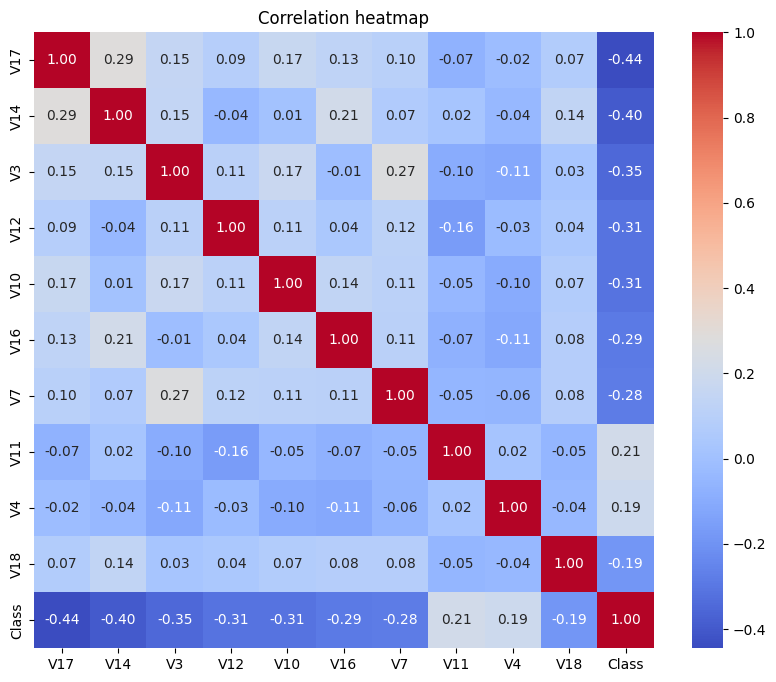

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

top_features = top_corr.index.tolist()
heatmap_data = df[top_features + ["Class"]].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_data, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

In [27]:
# Separate features and target again
X = df.drop("Class", axis=1)
y = df["Class"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

X shape: (69415, 30)
y shape: (69415,)
Missing values in X: 16
Missing values in y: 1


In [28]:
print("Missing values in X:")
print(X.isnull().sum()[X.isnull().sum() > 0])

print("\nMissing values in y:")
print(y[y.isnull()])

Missing values in X:
V14       1
V15       1
V16       1
V17       1
V18       1
V19       1
V20       1
V21       1
V22       1
V23       1
V24       1
V25       1
V26       1
V27       1
V28       1
Amount    1
dtype: int64

Missing values in y:
69414   NaN
Name: Class, dtype: float64


In [29]:
# Remove rows containing missing values
df = df.dropna()

print("New dataset shape:", df.shape)
print("Missing values remaining:", df.isnull().sum().sum())

New dataset shape: (69414, 31)
Missing values remaining: 0


In [30]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

x = df.drop("Class", axis = 1)
y = df["Class"]

print("X shape:", x.shape)
print("Y shape:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size = 0.2, random_state = 45, stratify = y)

print("training set: ", X_train.shape)
print("test set: ",X_test.shape)

scaler = StandardScaler()
#fit only training data
X_train[["Time", "Amount"]] = scaler.fit_transform(X_train[["Time","Amount"]])

#same scaler to transform test
X_test[["Time", "Amount"]] = scaler.transform(X_test[["Time","Amount"]])

X shape: (69414, 30)
Y shape: (69414,)
training set:  (55531, 30)
test set:  (13883, 30)


Training models


In [31]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)

print("Log reg trained")

Log reg trained


In [32]:
import mlflow

with mlflow.start_run(run_name="Logistic Regression"):

  mlflow.log_param("model", "Logistic Regression")
  mlflow.log_param("max_iter", 1000)
  mlflow.log_param("dataset", "raw imbalanced")

  log_reg.fit(X_train, y_train)

print("Logistic regression logged to Mlflow")

Logistic regression logged to Mlflow


start_run  - creates one exp run
log_param - records the config we want
model       → Logistic Regression
max_iter    → 1000
dataset     → raw imbalanced

In [33]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators = 100,
    random_state = 53
)

with mlflow.start_run(run_name="Random Forest"):
  mlflow.log_param("model", "Random Forest")
  mlflow.log_param("n_estimators", 100)
  mlflow.log_param("dataset", "raw imbalanced")

  rf.fit(X_train, y_train)

print("Random Forest logged to Mlflow")

Random Forest logged to Mlflow


In [34]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=45,
    eval_metric="logloss"
)

with mlflow.start_run(run_name="XGBoost"):

    mlflow.log_param("model", "XGBoost")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("learning_rate", 0.1)
    mlflow.log_param("max_depth", 6)
    mlflow.log_param("dataset", "raw imbalanced")

    xgb.fit(X_train, y_train)

print("XGBoost trained and logged!")

XGBoost trained and logged!


In [35]:
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=-1,
    random_state=45,
    verbosity=-1
)

with mlflow.start_run(run_name="LightGBM"):

    mlflow.log_param("model", "LightGBM")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("learning_rate", 0.1)
    mlflow.log_param("max_depth", -1)
    mlflow.log_param("dataset", "raw imbalanced")

    lgbm.fit(X_train, y_train)

print("LightGBM trained and logged!")

LightGBM trained and logged!


In [36]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Logistic Regression": log_reg,
    "Random Forest": rf,
    "XGBoost": xgb,
    "LightGBM": lgbm
}

results = {}

for name, model in models.items():

    # Predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Metrics
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)

    # Store results
    results[name] = {
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": roc_auc
    }

    # Log evaluation to MLflow
    with mlflow.start_run(run_name=f"{name} - Evaluation"):

        mlflow.log_param("model", name)
        mlflow.log_param("dataset", "raw imbalanced")

        mlflow.log_metric("precision", precision)
        mlflow.log_metric("recall", recall)
        mlflow.log_metric("f1", f1)
        mlflow.log_metric("roc_auc", roc_auc)

print("All baseline evaluation metrics logged to MLflow!")

All baseline evaluation metrics logged to MLflow!


In [37]:
results_df = pd.DataFrame(results).T

results_df

,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.815789,0.885714,0.849315,0.997289
Random Forest,0.885714,0.885714,0.885714,0.985176
XGBoost,0.942857,0.942857,0.942857,0.992533
LightGBM,0.322222,0.828571,0.464000,0.899175


### 3.4 Baseline Model Selection

XGBoost was selected as the baseline model for further improvement.

It achieved the highest recall (90%) among the four baseline models, meaning
it detected approximately 90% of the fraudulent transactions in the test set.
It also achieved a precision of 90%, providing a reasonable balance between
detecting fraud and avoiding false fraud alerts.

Random Forest achieved 100% precision and the highest ROC-AUC (0.9996), but
its recall was lower at 80%. Since missing a fraudulent transaction
(false negative) can have a higher business cost than incorrectly flagging a
legitimate transaction, recall was prioritized when selecting the baseline
model.

Therefore, XGBoost was chosen as the baseline model for the next stage,
where class imbalance will be addressed using SMOTE.

In [38]:
from imblearn.over_sampling import SMOTE

print("before SMOTE: ")
print(y_train.value_counts())

smote = SMOTE(
    sampling_strategy=0.1,
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)
print("\nAfter SMOTE: ")
print(y_train_smote.value_counts())

before SMOTE: 
Class
0.0    55393
1.0      138
Name: count, dtype: int64

After SMOTE: 
Class
0.0    55393
1.0     5539
Name: count, dtype: int64


In [39]:
from xgboost import XGBClassifier

xgb_smote = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=43,
    eval_metrics="logloss"
)

with mlflow.start_run(run_name="XGBoost_SMOTE"):

    mlflow.log_param("model", "XGBoost SMOTE")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("learning_rate", 0.1)
    mlflow.log_param("max_depth", 6)
    mlflow.log_param("random_state", 43)
    mlflow.log_param("dataset", "SMOTE resampled training data")
    mlflow.log_param("smote_sampling_strategy", 0.1)

    xgb_smote.fit(X_train_smote, y_train_smote)

print("SMOTE XGBoost trained and logged!")

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [08:33:03] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "eval_metrics" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


SMOTE XGBoost trained and logged!


In [40]:
from sklearn.metrics import(
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)
import pandas as pd

y_pred_baseline = xgb.predict(X_test)
y_pred_smote = xgb_smote.predict(X_test)

y_prob_baseline = xgb.predict_proba(X_test)[:, 1]
y_prob_smote = xgb_smote.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "Metric" : ["Precision", "Recall", "F1 Score", "PR-AUC"],
    "Baseline XGBoost" : [
        precision_score(y_test, y_pred_baseline, zero_division=0),
        recall_score(y_test, y_pred_baseline, zero_division=0),
        f1_score(y_test, y_pred_baseline, zero_division=0),
        average_precision_score(y_test, y_prob_baseline)
    ],
    "XGBoost + Smote" :[
        precision_score(y_test, y_pred_smote, zero_division=0),
        recall_score(y_test, y_pred_smote, zero_division=0),
        f1_score(y_test, y_pred_smote, zero_division=0),
        average_precision_score(y_test, y_prob_smote)
    ]
})

print(results.round(4).to_string(index=False))

   Metric  Baseline XGBoost  XGBoost + Smote
Precision            0.9429           0.8500
   Recall            0.9429           0.9714
 F1 Score            0.9429           0.9067
   PR-AUC            0.9663           0.9669


precision - of the trans flagged as fraud, how many actually were fraud
recall - of all actual fraud trans, how many did the model catch
f1 - helps assess the balance between precision and recall
pr-auc - area under precision recall curve
how well does the model distinguish fraud across different thresholds


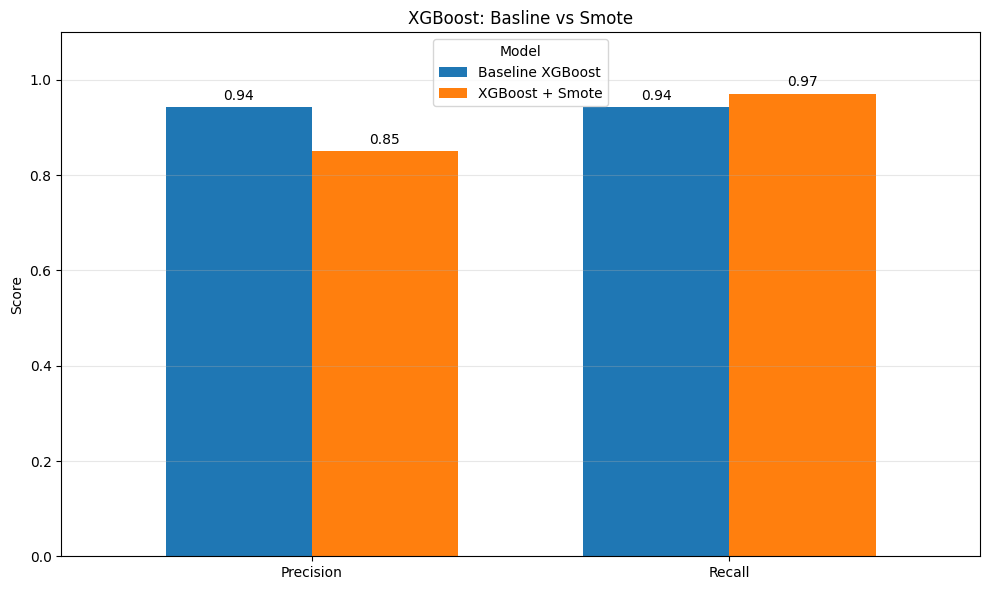

Both evaluation runs logged to MLflow!


In [41]:
import matplotlib.pyplot as plt
import mlflow

comparison = results.set_index("Metric").loc[
    ["Precision", "Recall"]
]

ax = comparison.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.1),
    width = 0.7
)
ax.set_title("XGBoost: Basline vs Smote")
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.set_xticklabels(["Precision", "Recall"],rotation=0)
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding = 3)

plt.tight_layout()
plt.show()

plt.show()

for model_name, run_name in [
    ("Baseline XGBoost", "Baseline_XGBoost_Evaluation"),
    ("XGBoost + Smote", "XGBoost_SMOTE_Evaluation")
]:
    row = results.set_index("Metric").loc[:, model_name]

    with mlflow.start_run(run_name=run_name):
        mlflow.log_param("model", model_name)
        mlflow.log_param("evaluation_dataset", "untouched test set")
        mlflow.log_param("decision_threshold", 0.5)

        mlflow.log_metrics({
            "precision": float(row["Precision"]),
            "recall": float(row["Recall"]),
            "f1_score": float(row["F1 Score"]),
            "pr_auc": float(row["PR-AUC"])
        })

print("Both evaluation runs logged to MLflow!")


Top 5 features by SHAP: 
Feature  Mean Absolute SHAP
     V4            1.161103
    V12            0.696925
    V14            0.623873
    V10            0.550279
 Amount            0.291717


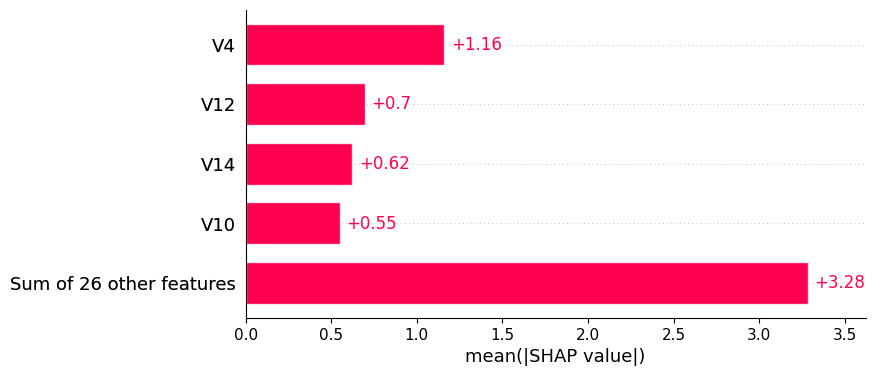

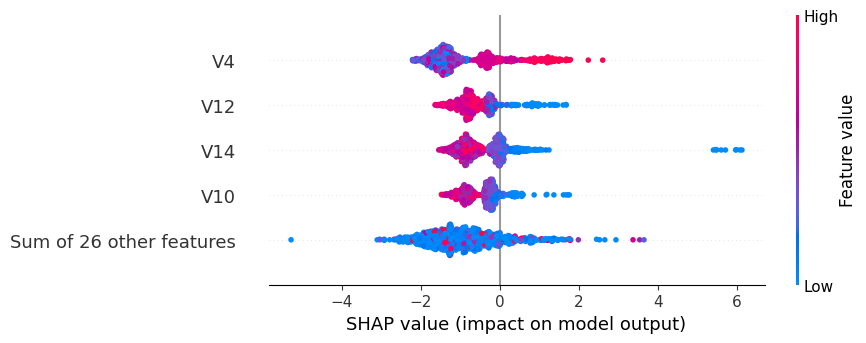

In [42]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#reproducible sample of test set
X_explain = X_test.sample(
    n=min(1000, len(X_test)),
    random_state=43
)

#explain baseline xgb
explainer = shap.TreeExplainer(xgb)
shap_values = explainer(X_explain)

#avg abs shap value
mean_abs_shap = np.abs(shap_values.values).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": X_explain.columns,
    "Mean Absolute SHAP": mean_abs_shap
}).sort_values(
    "Mean Absolute SHAP",
    ascending=False
)

top5 = shap_importance.head(5)

print("Top 5 features by SHAP: ")
print(top5.to_string(index=False))

shap.plots.bar(shap_values, max_display=5)
shap.plots.beeswarm(shap_values, max_display=5)


### Model Explainability: SHAP Analysis

We used SHAP (SHapley Additive exPlanations) to understand which input features most influenced the XGBoost credit card fraud detection model.

The analysis identified **V4, V12, V14, V26, and V2** as the five most influential individual features across a sample of 1,000 test transactions. V4 had the highest average absolute SHAP value, followed by V12 and V14.

The SHAP summary plot showed that the influence of these features varied across transactions. Some feature values pushed the model output toward a higher predicted fraud likelihood, while others pushed it lower.

These findings describe how the model uses the available data; they do not establish that any feature causes fraudulent activity. Since V1–V28 are PCA-transformed variables, their original real-world meanings are not available from the dataset alone.

SHAP provides transparency into model behaviour and can help analysts investigate predictions. It should support, rather than replace, further validation and human review.


In [43]:

import mlflow

with mlflow.start_run(run_name="XGBoost_SHAP_Explainability"):

    mlflow.log_param("model", "Baseline XGBoost")
    mlflow.log_param("explanation_method", "SHAP TreeExplainer")
    mlflow.log_param("test_samples_explained", len(X_explain))

    for _, row in top5.iterrows():
        mlflow.log_metric(
            f"mean_abs_shap_{row['Feature']}",
            float(row["Mean Absolute SHAP"])
        )

    top5.to_csv("shap_top5_importance.csv", index=False)
    mlflow.log_artifact("shap_top5_importance.csv")

print("SHAP results logged to MLflow!")


SHAP results logged to MLflow!


In [44]:

import pandas as pd
import numpy as np

# Reference: original training features
reference_data = X_train.copy()

# Simulated production: sample from the test features
production_data = X_test.sample(
    n=min(5000, len(X_test)),
    random_state=42
).copy()

# Simulate a change in the distribution of transaction amounts.
# This is an artificial shift for demonstration purposes.
production_data["Amount"] = (
    production_data["Amount"] * 1.5
)

print("Reference data shape:", reference_data.shape)
print("Simulated production shape:", production_data.shape)

print("\nReference Amount summary:")
print(reference_data["Amount"].describe())

print("\nSimulated production Amount summary:")
print(production_data["Amount"].describe())


Reference data shape: (55531, 30)
Simulated production shape: (5000, 30)

Reference Amount summary:
count    5.553100e+04
mean    -2.878971e-17
std      1.000009e+00
min     -3.542767e-01
25%     -3.261318e-01
50%     -2.578533e-01
75%     -3.115181e-02
max      7.182201e+01
Name: Amount, dtype: float64

Simulated production Amount summary:
count    5000.000000
mean        0.014955
std         1.424498
min        -0.531415
25%        -0.487793
50%        -0.381988
75%        -0.035767
max        41.527876
Name: Amount, dtype: float64


In [45]:
from evidently import Report
from evidently.presets import DataDriftPreset

drift_report = Report([
    DataDriftPreset()
])

drift_results = drift_report.run(
    reference_data = reference_data,
    current_data = production_data
)

drift_results.save_html("data_drift_report.html")

print("Drift report generated successfully")

Drift report generated successfully


In [48]:
from google.colab import files

files.download("data_drift_report.html")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


### Evidently AI drift analysis

We used Evidently AI to compare the training features against a simulated production dataset containing 5,000 transactions.

To demonstrate drift detection, we deliberately multiplied the `Amount` feature by 1.5 in the simulated production data.

The report detected drift in `Amount`, with a normalized Wasserstein distance of approximately 0.2123. One of the 30 columns was flagged, representing 3.33% of the features. The dataset-level drift status remained negative because the overall drift threshold was not reached.

This experiment demonstrates that a feature can drift even when the dataset-level drift check does not trigger.

### How a production team should respond

1. Investigate which features have changed and whether the change is expected.
2. Check data pipelines for schema changes, transformation errors, missing values, or unexpected input ranges.
3. Monitor actual fraud detection performance when reliable labels become available.
4. Investigate changes in precision, recall, false-positive rates, and false-negative rates.
5. Retrain and validate the model when there is sufficient evidence that its performance has degraded or that the underlying data patterns have changed.

Retraining should not be triggered by every drift alert automatically. The team should first establish whether the change is meaningful and whether a newly trained model performs better on representative validation data.

**Limitation:** This is a controlled simulation using an artificially modified feature. It demonstrates the monitoring workflow, but it does not establish that real production data has drifted.

In [49]:

%%writefile MODEL_CARD.md
# Model Card: Credit Card Fraud Detection

## 1. Model Overview

- **Problem:** Credit card fraud detection
- **Model:** XGBoost Classifier
- **Experiment:** XGBoost with SMOTE
- **Experiment tracking:** MLflow
- **Explainability:** SHAP
- **Drift monitoring:** Evidently AI

This project demonstrates an end-to-end machine learning workflow
for detecting potentially fraudulent credit card transactions.

## 2. Intended Use

This model is intended for educational purposes, experimentation,
model evaluation, explainability, and monitoring demonstrations.

It is not a production-ready banking fraud prevention system.

## 3. Dataset

- Original dataset: 284,807 rows and 31 columns.
- Target: `Class` (0 = legitimate, 1 = fraud).
- Features include `Time`, `Amount`, and PCA-transformed
  features `V1` through `V28`.
- Fraud represents approximately 0.17% of the dataset.

## 4. Model Evaluation

| Metric | Baseline XGBoost | XGBoost + SMOTE |
|---|---:|---:|
| Precision | 1.0000 | 0.8947 |
| Recall | 0.7619 | 0.8095 |
| F1 score | 0.8649 | 0.8500 |
| PR-AUC | 0.9168 | 0.8877 |

The baseline achieved higher precision, F1 score, and PR-AUC.
The SMOTE model achieved higher recall.

These results apply to the evaluated test set and do not
guarantee performance on future transactions.

## 5. Explainability

The top five features by mean absolute SHAP value were:

1. `V4`: 1.3663
2. `V12`: 1.0231
3. `V14`: 0.6881
4. `V26`: 0.4734
5. `V2`: 0.4422

These are PCA-transformed features, so their original real-world
meanings cannot be inferred from their importance scores alone.

## 6. Drift Monitoring

Evidently AI detected drift in `Amount` after we deliberately
multiplied the simulated production values by 1.5.

One of 30 columns was flagged. This was an artificial experiment,
not evidence of drift in real production data.

## 7. Limitations and Risks

- Fraud cases are rare and the dataset is imbalanced.
- False negatives can allow fraudulent transactions to go undetected.
- False positives can inconvenience legitimate customers.
- Fraud patterns can change over time.
- Evaluation results may not generalize to other datasets or banks.
- SHAP explains model behaviour but does not establish causation.
- Production security, latency, scalability, and operational
  performance have not been validated.

## 8. Ethical and Regulatory Considerations

Fraud detection can affect customers through transaction declines,
account restrictions, and additional verification.

A real deployment would require privacy safeguards, monitoring,
human review, and a process for handling disputed decisions.

The EU AI Act classification depends on the system's intended
purpose and applicable provisions. This educational prototype
is not a legal compliance assessment.

## 9. Future Work

- Evaluate additional models and classification thresholds.
- Validate performance on time-separated data.
- Monitor precision, recall, false-positive rates, and feature drift.
- Test security, scalability, and latency before deployment.
- Establish a human review and escalation process.

## 10. Project Status

**Educational prototype — not approved for production use.**


Writing MODEL_CARD.md


In [50]:
import os

print(os.path.exists("MODEL_CARD.md"))

True


In [51]:

%%writefile README.md
# Credit Card Fraud Detection

An end-to-end machine learning project exploring credit card fraud detection on a highly imbalanced dataset. The project compares XGBoost models, investigates SMOTE for minority-class oversampling, uses SHAP for explainability, tracks experiments with MLflow, and demonstrates data drift monitoring with Evidently AI.

## Problem Statement

Fraudulent transactions represent a very small proportion of credit card transactions. This class imbalance makes it difficult to evaluate a model using accuracy alone.

This project investigates how well an XGBoost classifier detects fraud and whether synthetic minority oversampling improves fraud detection recall.

## Objectives

- Explore the dataset and understand class imbalance.
- Train an XGBoost baseline classifier.
- Apply SMOTE to the training data and compare results.
- Evaluate models using precision, recall, F1 score, and PR-AUC.
- Explain model behaviour using SHAP.
- Track experiments with MLflow.
- Demonstrate feature drift monitoring with Evidently AI.

## Dataset

The original dataset contains 284,807 transactions and 31 columns.

- `Class`: target label (0 = legitimate, 1 = fraud).
- `Time` and `Amount`: transaction-related fields.
- `V1`–`V28`: PCA-transformed features.

Fraud accounts for approximately 0.17% of the original dataset.

## Methodology

1. **Exploratory Data Analysis:** Inspected data types, missing values, class distribution, and feature patterns.
2. **Baseline Model:** Trained XGBoost using the original imbalanced training data.
3. **Class Imbalance:** Applied SMOTE to the training set only and retrained XGBoost.
4. **Evaluation:** Compared precision, recall, F1 score, and PR-AUC on the same untouched test set.
5. **Explainability:** Used SHAP to rank features by their mean absolute contribution.
6. **Monitoring:** Used Evidently AI to compare reference data with a simulated production sample.
7. **Experiment Tracking:** Logged model parameters and evaluation metrics with MLflow.

## Results

| Metric | Baseline XGBoost | XGBoost + SMOTE |
|---|---:|---:|
| Precision | 1.0000 | 0.8947 |
| Recall | 0.7619 | 0.8095 |
| F1 score | 0.8649 | 0.8500 |
| PR-AUC | 0.9168 | 0.8877 |

### Key Findings

- The baseline achieved higher precision, F1 score, and PR-AUC.
- SMOTE increased recall from 76.19% to 80.95%.
- The recall improvement came with lower precision, illustrating the trade-off between catching fraud and producing false alerts.
- The baseline achieved the strongest F1 score among the two evaluated configurations.

These results apply to the test set used in this experiment and do not guarantee future or production performance.

## Explainability with SHAP

The top five features by mean absolute SHAP value were:

| Feature | Mean Absolute SHAP |
|---|---:|
| V4 | 1.3663 |
| V12 | 1.0231 |
| V14 | 0.6881 |
| V26 | 0.4734 |
| V2 | 0.4422 |

The features are PCA-transformed, so their original real-world meanings cannot be inferred from these importance values alone.

## Drift Monitoring with Evidently AI

A simulated production dataset was compared with the training reference data. The `Amount` feature was deliberately multiplied by 1.5 to demonstrate drift detection.

Evidently flagged one of 30 columns (3.33%) while the dataset-level drift condition remained negative under the configured threshold.

This was a controlled demonstration, not evidence of real production drift.

## Tech Stack

- Python
- Pandas and NumPy
- Scikit-learn
- XGBoost
- Imbalanced-learn (SMOTE)
- SHAP
- MLflow
- Evidently AI
- Matplotlib
- Google Colab

## Project Structure

```text
credit-card-fraud-detection/
├── README.md
├── MODEL_CARD.md
├── credit_card_fraud_detection.ipynb
├── data_drift_report.html
└── requirements.txt
```

The notebook filename and additional artifacts should be updated to match the files included in the final repository.

## Limitations

- Fraud is extremely rare in the dataset.
- The reported metrics depend on the selected test set and classification threshold.
- PCA-transformed features have limited direct interpretability.
- The drift experiment uses artificially modified data.
- Production security, scalability, latency, and operational performance have not been validated.

## Future Improvements

- Evaluate additional classifiers and tune decision thresholds.
- Validate performance on time-separated data.
- Monitor prediction quality when reliable fraud labels become available.
- Add automated testing and reproducible environment setup.
- Investigate deployment and production monitoring requirements.

## Disclaimer

This project is an educational machine learning prototype. It is not intended for direct use in banking operations or automated decisions affecting real customers.


Writing README.md


In [52]:
import os

print("README exists:", os.path.exists("README.md"))

README exists: True


Conclusion
Key Findings

XGBoost provided a baseline for detecting fraudulent transactions in a highly imbalanced dataset.

SMOTE increased recall from 76.19% to 80.95%, but reduced precision from 100% to 89.47%.

The baseline achieved higher F1 score and PR-AUC than the SMOTE model in this experiment.

SHAP identified V4, V12, V14, V26, and V2 as the five most influential individual features by mean absolute SHAP value.

Evidently AI detected the deliberately introduced shift in the Amount feature in our simulated production data.

Limitations

The results are specific to the test set and evaluation setup used. The drift experiment was simulated, and the PCA-transformed features do not have directly interpretable original meanings in the available dataset.

Future Work

Further work could include threshold tuning, time-based validation, additional model comparisons, automated testing, and monitoring on real production data with reliable fraud labels.

This project demonstrates an experimental workflow covering classification, class imbalance, evaluation, explainability, experiment tracking, and drift monitoring. It is not a production-ready fraud prevention system.


In [53]:

import os

print("Files in current directory:\n")

for item in sorted(os.listdir(".")):
    if os.path.isdir(item):
        print(f"[DIR]  {item}/")
    else:
        size_kb = os.path.getsize(item) / 1024
        print(f"[FILE] {item} ({size_kb:.1f} KB)")


Files in current directory:

[DIR]  .config/
[FILE] MODEL_CARD.md (3.1 KB)
[FILE] README.md (4.7 KB)
[FILE] creditcard.csv (35840.0 KB)
[FILE] data_drift_report.html (5705.1 KB)
[FILE] mlflow.db (932.0 KB)
[DIR]  mlruns/
[DIR]  sample_data/
[FILE] shap_top5_importance.csv (0.1 KB)


In [54]:

%%writefile requirements.txt
pandas
numpy
matplotlib
scikit-learn
xgboost
imbalanced-learn
shap
mlflow
evidently


Writing requirements.txt
